# 6BUIS017W CWK1, Task 1: Data Preparation and Feature Engineering


In [38]:
# Setup and package versions
!pip install -q yfinance lxml

In [39]:
import os, sys, platform, json, datetime as dt
from io import StringIO
import numpy as np
import pandas as pd
import requests
import yfinance as yf

START = "2021-01-01"          # inclusive
END = "2025-01-01"
BENCH = "^GSPC"
OUT = "data_snapshot"
os.makedirs(OUT, exist_ok=True)
RETRIEVAL_DATE = dt.date.today().isoformat()

versions = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "pandas": pd.__version__, "numpy": np.__version__,
    "yfinance": yf.__version__, "requests": requests.__version__,
    "retrieval_date": RETRIEVAL_DATE, "study_start": START, "study_end_exclusive": END,
}
json.dump(versions, open(f"{OUT}/package_versions.json", "w"), indent=2)
print("Settings saved to", f"{OUT}/package_versions.json")

Settings saved to data_snapshot/package_versions.json


### Table display helper


In [40]:
from IPython.display import display

def show(data, title, fmt=None, index=True, precision=4):
    """Display a DataFrame or Series as a standard Colab table with a title line above it."""
    frame = data.to_frame() if isinstance(data, pd.Series) else data.copy()
    fmt_cell = lambda f: (lambda v: f.format(v) if isinstance(v, (int, float, np.number)) and pd.notna(v) else v)
    if isinstance(fmt, dict):
        for col, f in fmt.items():
            if col in frame.columns:
                frame[col] = frame[col].map(fmt_cell(f))
    elif isinstance(fmt, str):
        frame = frame.apply(lambda col: col.map(fmt_cell(fmt)))
    if fmt is None or isinstance(fmt, dict):
        num = frame.select_dtypes("number").columns
        frame[num] = frame[num].round(precision)
    if not index:
        frame = frame.set_index(frame.columns[0])
    print(title)
    display(frame)

def facts(title, items):
    """Display key results as a two column table: what was checked and the result."""
    show(pd.DataFrame({"Check": list(items.keys()), "Result": [str(v) for v in items.values()]}), title, index=False)

In [41]:
show(pd.DataFrame(list(versions.items()), columns=["Item", "Value"]), "Package versions and study settings", index=False)

Package versions and study settings


,Value
Item,
python,3.13.18
platform,Linux-6.6.159+-x86_64-with-glibc2.39
pandas,2.2.3
numpy,2.4.6
yfinance,0.2.66
requests,2.32.4
retrieval_date,2026-11-23
study_start,2021-01-01
study_end_exclusive,2025-01-01


## 1.1 Ticker selection and data acquisition



In [42]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (6BUIS017W coursework)"}, timeout=30).text
try:
    sp500 = pd.read_html(StringIO(html), attrs={"id": "constituents"})[0]
except ValueError:
    sp500 = pd.read_html(StringIO(html))[0]

sp500["yf_ticker"] = sp500["Symbol"].astype(str).str.strip().str.replace(".", "-", regex=False)
sp500["retrieval_date"] = RETRIEVAL_DATE
sp500.to_csv(f"{OUT}/sp500_constituents_{RETRIEVAL_DATE}.csv", index=False)
facts("1.1 Constituent list", {"Retrieval date": RETRIEVAL_DATE, "Tickers retrieved": len(sp500),
                               "Duplicate symbols": int(sp500["yf_ticker"].duplicated().sum()),
                               "Example ticker conversion": "BRK.B -> BRK-B"})
show(sp500[["Symbol", "yf_ticker", "Security", "GICS Sector"]].head(), "First five constituents", index=False)

1.1 Constituent list


,Result
Check,
Retrieval date,2026-11-23
Tickers retrieved,503
Duplicate symbols,0
Example ticker conversion,BRK.B -> BRK-B


First five constituents


,yf_ticker,Security,GICS Sector
Symbol,,,
MMM,MMM,3M,Industrials
AOS,AOS,A. O. Smith,Industrials
ABT,ABT,Abbott Laboratories,Health Care
ABBV,ABBV,AbbVie,Health Care
ACN,ACN,Accenture,Information Technology


In [75]:
# Download daily OHLC, Adj Close, Volume, Dividends, Stock Splits.
SNAP = f"{OUT}/daily_prices_long.csv.gz"
tickers = sp500["yf_ticker"].tolist() + [BENCH]

def download_prices(tickers):
    raw = yf.download(tickers, start=START, end=END, interval="1d", auto_adjust=False,
                      actions=True, group_by="column", threads=True, progress=False)
    long = raw.stack(level=1, future_stack=True).reset_index()
    long.columns = ["Date", "Ticker"] + list(long.columns[2:])
    return long

if os.path.exists(SNAP):
    long = pd.read_csv(SNAP, parse_dates=["Date"])
    SOURCE_MSG = "loaded cached snapshot " + SNAP
else:
    long = download_prices(tickers)
    long.to_csv(SNAP, index=False)
    SOURCE_MSG = "downloaded from yfinance and saved to " + SNAP

long["Date"] = pd.to_datetime(long["Date"]).dt.tz_localize(None)
no_data = long.groupby("Ticker")["Adj Close"].apply(lambda x: x.notna().sum() == 0)
no_data = sorted(no_data[no_data].index)
facts("1.1 Daily price download", {"Data": SOURCE_MSG, "Rows": f"{len(long):,}", "Tickers (shares + ^GSPC)": long["Ticker"].nunique(),
                                   "First date": long["Date"].min().date(), "Last date": long["Date"].max().date(),
                                   "Tickers with no data": f"{len(no_data)}: " + (", ".join(no_data) if no_data else "none")})
show(long.head(), "First rows of the daily price snapshot", index=False, precision=2)

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'FDXF', 'VYLR', 'Q', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


1.1 Daily price download


,Result
Check,
Data,downloaded from yfinance and saved to data_sna...
Rows,"506,520"
Tickers (shares + ^GSPC),504
First date,2021-01-04
Last date,2024-12-31
Tickers with no data,"5: FDXF, HONA, Q, SNDK, VYLR"


First rows of the daily price snapshot


,Ticker,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,,
2021-01-04,A,114.01,118.64,0.19,120.09,117.11,118.94,0.0,2030700.0
2021-01-04,AAPL,125.54,129.41,0.00,133.61,126.76,133.52,0.0,143301900.0
2021-01-04,ABBV,84.22,105.41,0.00,107.35,103.86,107.18,0.0,9523400.0
2021-01-04,ABNB,139.15,139.15,0.00,151.01,137.00,150.99,0.0,6409900.0
2021-01-04,ABT,97.27,109.11,0.00,110.25,107.26,109.53,0.0,6192000.0


In [44]:
def wide(field):
    return long.pivot_table(index="Date", columns="Ticker", values=field, aggfunc="first").sort_index()

adj = wide("Adj Close"); close = wide("Close"); vol = wide("Volume")
divs = wide("Dividends") if "Dividends" in long else pd.DataFrame(index=adj.index)
splits = wide("Stock Splits") if "Stock Splits" in long else pd.DataFrame(index=adj.index)

# Trading calendar = dates on which the benchmark traded
cal = adj[BENCH].dropna().index
facts("Trading calendar (^GSPC trading sessions)", {"Trading sessions": len(cal), "First session": cal.min().date(), "Last session": cal.max().date()})

Trading calendar (^GSPC trading sessions)


,Result
Check,
Trading sessions,1005
First session,2021-01-04
Last session,2024-12-31


## 1.2 Data validation and alignment


In [45]:
MAX_MISSING = 0
dup_dates_total = int(long.duplicated(["Date", "Ticker"]).sum())

rows = []
for t in sp500["yf_ticker"]:
    r = {"ticker": t}
    if t not in adj.columns or adj[t].dropna().empty:
        r.update(status="excluded", reason="no data returned by source"); rows.append(r); continue
    a, c, v = adj[t].reindex(cal), close[t].reindex(cal), vol[t].reindex(cal)
    r["first_date"] = a.first_valid_index().date(); r["last_date"] = a.last_valid_index().date()
    r["missing_adj"] = int(a.isna().sum()); r["missing_close"] = int(c.isna().sum()); r["missing_vol"] = int(v.isna().sum())
    r["nonpositive_price"] = int(((a <= 0) | (c <= 0)).sum())
    r["neg_vol"] = int((v < 0).sum()); r["zero_vol"] = int((v == 0).sum())
    r["n_splits"] = int((splits[t].fillna(0) > 0).sum()) if t in splits else 0
    r["split_dates"] = ";".join(str(d.date()) for d in splits.index[splits[t].fillna(0) > 0]) if t in splits else ""
    r["n_dividends"] = int((divs[t].fillna(0) > 0).sum()) if t in divs else 0
    # Corporate action consistency: yfinance Close is split adjusted but not dividend adjusted.
    # A split that was NOT adjusted would show a huge one day Close move on the split date.
    cret = c.pct_change(fill_method=None)
    r["max_abs_daily_close_ret"] = round(float(cret.abs().max()), 4)
    big = cret[cret.abs() > 0.40]
    r["big_moves_on_split_dates"] = int(sum(d.date().isoformat() in r["split_dates"] for d in big.index))
    # Adj Close / Close ratio should only step on dividend dates
    ratio_step = (a / c).pct_change(fill_method=None).abs()
    r["max_adj_ratio_step"] = round(float(ratio_step.max()), 4)

    reason = []
    if adj.index.duplicated().any(): reason.append("duplicate dates")
    if max(r["missing_adj"], r["missing_close"], r["missing_vol"]) > MAX_MISSING:
        reason.append(f"incomplete history ({r['first_date']} to {r['last_date']}, {r['missing_adj']} missing sessions)")
    if r["nonpositive_price"]: reason.append("nonpositive price")
    if r["neg_vol"] or r["zero_vol"]: reason.append("volume error (negative or zero)")
    if r["big_moves_on_split_dates"]: reason.append("possible unadjusted split")
    r["status"] = "excluded" if reason else "included"; r["reason"] = "; ".join(reason)
    rows.append(r)

vlog = pd.DataFrame(rows).merge(sp500[["yf_ticker", "Security", "GICS Sector"]], left_on="ticker", right_on="yf_ticker", how="left").drop(columns="yf_ticker")
vlog.to_csv(f"{OUT}/inclusion_exclusion_log.csv", index=False)
included = vlog.loc[vlog.status == "included", "ticker"].tolist()
facts("1.2 Validation summary", {"Duplicate (Date, Ticker) rows": dup_dates_total, "Tickers checked": len(vlog),
                                "Included": len(included), "Excluded": int((vlog.status == "excluded").sum()),
                                "Missing prices filled": "none (excluded instead)"})
reason_type = vlog.loc[vlog.status == "excluded", "reason"].str.split(" \\(").str[0]
show(reason_type.value_counts().rename("Tickers").rename_axis("Exclusion reason"), "1.2 Exclusions by reason", precision=0)
show(vlog.loc[vlog.status == "excluded", ["ticker", "Security", "first_date", "last_date", "reason"]],
     "1.2 Excluded tickers and reasons", index=False)

1.2 Validation summary


,Result
Check,
"Duplicate (Date, Ticker) rows",0
Tickers checked,503
Included,486
Excluded,17
Missing prices filled,none (excluded instead)


1.2 Exclusions by reason


,Tickers
Exclusion reason,
incomplete history,10
no data returned by source,5
volume error,2


1.2 Excluded tickers and reasons


,Security,first_date,last_date,reason
ticker,,,,
APP,AppLovin,2021-04-15,2024-12-31,"incomplete history (2021-04-15 to 2024-12-31, ..."
COIN,Coinbase,2021-04-14,2024-12-31,"incomplete history (2021-04-14 to 2024-12-31, ..."
CEG,Constellation Energy,2022-01-19,2024-12-31,"incomplete history (2022-01-19 to 2024-12-31, ..."
EXE,Expand Energy,2021-02-10,2024-12-31,"incomplete history (2021-02-10 to 2024-12-31, ..."
FDXF,FedEx Freight,NaN,NaN,no data returned by source
FERG,Ferguson Enterprises,2021-01-04,2024-12-31,volume error (negative or zero)
GEHC,GE HealthCare,2022-12-15,2024-12-31,"incomplete history (2022-12-15 to 2024-12-31, ..."
GEV,GE Vernova,2024-03-27,2024-12-31,"incomplete history (2024-03-27 to 2024-12-31, ..."
HONA,Honeywell Aerospace,NaN,NaN,no data returned by source


In [46]:
# Corporate action summary and benchmark checks
b_adj, b_close = adj[BENCH].reindex(cal), close[BENCH].reindex(cal)
facts("1.2 Corporate action and benchmark checks", {
    "Shares with splits": int((vlog.n_splits > 0).sum()),
    "Split dates with a >40% Close jump (unadjusted split)": int(vlog.big_moves_on_split_dates.fillna(0).sum()),
    "Shares paying dividends": int((vlog.n_dividends > 0).sum()),
    "Benchmark missing sessions": int(b_adj.isna().sum()),
    "Benchmark max |Adj Close - Close| (0 = price index, no dividends)": float((b_adj - b_close).abs().max())})
split_tab = vlog.loc[vlog.n_splits > 0, ["ticker", "split_dates", "max_abs_daily_close_ret", "big_moves_on_split_dates"]].rename(
    columns={"split_dates": "Split dates", "max_abs_daily_close_ret": "Largest daily Close move", "big_moves_on_split_dates": "Unadjusted split flags"})
show(split_tab, "1.2 Shares with splits (0 flags = all split adjusted)", index=False,
     fmt={"Largest daily Close move": "{:.2%}", "Unadjusted split flags": "{:.0f}"})

1.2 Corporate action and benchmark checks


,Result
Check,
Shares with splits,53
Split dates with a >40% Close jump (unadjusted split),0
Shares paying dividends,399
Benchmark missing sessions,0
"Benchmark max |Adj Close - Close| (0 = price index, no dividends)",0.0


1.2 Shares with splits (0 flags = all split adjusted)


,Split dates,Largest daily Close move,Unadjusted split flags
ticker,,,
MMM,2024-04-01,22.99%,0
GOOGL,2022-07-18,10.22%,0
GOOG,2022-07-18,9.97%,0
AMZN,2022-06-06,14.05%,0
APH,2021-03-05;2024-06-12,8.79%,0
ANET,2021-11-18;2024-12-04,20.39%,0
T,2022-04-11,10.41%,0
BDX,2022-04-01,9.25%,0
TECH,2022-11-30,16.22%,0


## 1.3 Weekly return and weekly beta


In [47]:
first_day = pd.Timestamp(START); last_day = pd.Timestamp(END) - pd.Timedelta(days=1)
wk_px = adj[included + [BENCH]].reindex(cal).resample("W-FRI").last()
complete = (wk_px.index - pd.Timedelta(days=4) >= first_day) & (wk_px.index <= last_day)
dropped_weeks = wk_px.index[~complete]
wk_px = wk_px.loc[complete]
assert (wk_px.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all(), "gap in weekly labels"

# Holiday shortened weeks retained
sess_per_week = pd.Series(1, index=cal).resample("W-FRI").sum().reindex(wk_px.index)

wret = wk_px.pct_change(fill_method=None).iloc[1:]
wret.to_csv(f"{OUT}/weekly_returns.csv")
facts("1.3 Weekly resampling", {"Dropped incomplete weeks": ", ".join(str(d.date()) for d in dropped_weeks) or "none",
                               "Weekly price labels": f"{len(wk_px)} ({wk_px.index.min().date()} to {wk_px.index.max().date()})",
                               "Holiday shortened weeks kept": int((sess_per_week < 5).sum()),
                               "Weekly returns per share": f"{len(wret)} (first label {wret.index.min().date()})",
                               "Gaps between weekly labels": "none (all 7 days)"})

1.3 Weekly resampling


,Result
Check,
Dropped incomplete weeks,2025-01-03
Weekly price labels,208 (2021-01-08 to 2024-12-27)
Holiday shortened weeks kept,37
Weekly returns per share,207 (first label 2021-01-15)
Gaps between weekly labels,none (all 7 days)


In [48]:
b = wret[BENCH]
feat = []
for t in included:
    m = wret[t].notna() & b.notna()       # identical week labels for share and benchmark
    s, bb = wret.loc[m, t], b[m]
    n = int(m.sum())
    cov = np.cov(s, bb, ddof=1)[0, 1]; var_b = bb.var(ddof=1)
    beta = cov / var_b
    slope = np.polyfit(bb, s, 1)[0]      # independent check: OLS slope equals cov/var
    r2 = np.corrcoef(s, bb)[0, 1] ** 2
    se_beta = np.sqrt((1 - r2) / (n - 2)) * s.std(ddof=1) / bb.std(ddof=1)
    geo = (wk_px[t].iloc[-1] / wk_px[t].iloc[0]) ** (1 / n) - 1
    feat.append({"ticker": t, "n_weeks": n, "mean_weekly_return": s.mean(), "geometric_weekly_return": geo,
                 "weekly_return_std": s.std(ddof=1), "beta": beta, "beta_ols_check": slope,
                 "beta_se": se_beta, "r_squared": r2})
rb = pd.DataFrame(feat).set_index("ticker")
assert np.allclose(rb.beta, rb.beta_ols_check), "beta check failed"
facts("1.3 Beta checks", {"Aligned weeks per share": ", ".join(str(x) for x in rb.n_weeks.unique()),
                         "Benchmark mean weekly return": f"{b.mean():.4%}",
                         "Benchmark beta with itself": round(np.cov(b, b)[0, 1] / b.var(), 6),
                         "OLS slope equals cov/var for every share": bool(np.allclose(rb.beta, rb.beta_ols_check))})
show(rb[["n_weeks", "mean_weekly_return", "beta", "beta_se", "r_squared"]].describe(),
     "1.3 Summary of weekly return, beta, beta standard error and R squared")

1.3 Beta checks


,Result
Check,
Aligned weeks per share,207
Benchmark mean weekly return,0.2398%
Benchmark beta with itself,1.0
OLS slope equals cov/var for every share,True


1.3 Summary of weekly return, beta, beta standard error and R squared


,n_weeks,mean_weekly_return,beta,beta_se,r_squared
count,486.0,486.0000,486.0000,486.0000,486.0000
mean,207.0,0.0029,0.9737,0.1124,0.2798
std,0.0,0.0027,0.4073,0.0414,0.1312
min,207.0,-0.0045,0.0555,0.0568,0.0022
25%,207.0,0.0012,0.6666,0.0860,0.1718
50%,207.0,0.0026,0.9506,0.1007,0.2837
75%,207.0,0.0042,1.1795,0.1273,0.3798
max,207.0,0.0178,3.7786,0.4362,0.6387


## 1.4 Adapted RFM


In [49]:
common = close[included].reindex(cal).notna().all(axis=1) & vol[included].reindex(cal).notna().all(axis=1) & adj[BENCH].reindex(cal).notna()
OBS_DATE = cal[common.values][-1]
win = cal[cal <= OBS_DATE][-60:]

V = vol[included].reindex(cal)
C = close[included].reindex(cal)
baseline = V.shift(1).rolling(20, min_periods=20).mean()   # preceding 20 sessions, current day excluded
threshold = 2 * baseline
event = (V > threshold) & threshold.notna()

rfm = []
for t in included:
    hist = event.loc[:OBS_DATE, t]
    ev_dates = hist.index[hist]
    enough = V.loc[:OBS_DATE, t].notna().sum() >= 80 and threshold.loc[win, t].notna().all()
    last_ev = ev_dates.max() if len(ev_dates) else pd.NaT
    R = (OBS_DATE - last_ev).days if pd.notna(last_ev) else np.nan
    F = int(event.loc[win, t].sum())
    M = float((C.loc[win, t] * V.loc[win, t]).sum())
    rfm.append({"ticker": t, "last_event_date": last_ev, "R_days": R, "F_days": F, "M_usd": M,
                "n_events_full_history": len(ev_dates), "sufficient_history_80": enough})
rfm = pd.DataFrame(rfm).set_index("ticker")
facts("1.4 RFM setup", {"Observation date": OBS_DATE.date(), "60 session window": f"{win[0].date()} to {win[-1].date()}",
                       "Shares with no event (R missing)": int(rfm.R_days.isna().sum()),
                       "Shares lacking 80 sessions of history": int((~rfm.sufficient_history_80).sum()),
                       "Most common latest event date": rfm.last_event_date.mode()[0].date()})
show(rfm[["R_days", "F_days", "M_usd", "n_events_full_history"]].assign(M_usd=rfm.M_usd / 1e9).rename(columns={"M_usd": "M_usd_bn"}).describe(),
     "1.4 Summary of R (days), F (days) and M (USD billion)", precision=2)

1.4 RFM setup


,Result
Check,
Observation date,2024-12-31
60 session window,2024-10-07 to 2024-12-31
Shares with no event (R missing),0
Shares lacking 80 sessions of history,0
Most common latest event date,2024-12-20


1.4 Summary of R (days), F (days) and M (USD billion)


,R_days,F_days,M_usd_bn,n_events_full_history
count,486.00,486.00,486.00,486.00
mean,20.41,2.99,39.40,37.61
std,21.34,1.33,129.14,9.55
min,4.00,0.00,1.30,15.00
25%,11.00,2.00,10.20,31.00
50%,11.00,3.00,16.68,37.00
75%,14.75,4.00,32.28,44.00
max,222.00,8.00,1847.70,75.00


In [50]:
# Threshold alignment check: recompute one baseline by hand and confirm the current day is excluded
t0 = included[0]; i = cal.get_loc(win[0])
manual = V[t0].iloc[i - 20:i].mean()
assert np.isclose(manual, baseline.loc[win[0], t0]), "baseline misaligned"
facts("1.4 Threshold alignment check", {"Share": t0, "Date": win[0].date(),
                                       "Manual mean of previous 20 sessions": f"{manual:,.0f}",
                                       "Rolling baseline in code": f"{baseline.loc[win[0], t0]:,.0f}",
                                       "Result": "match, current day excluded, no look ahead"})
assert event.loc[:OBS_DATE].shape[0] == cal[cal <= OBS_DATE].shape[0]

1.4 Threshold alignment check


,Result
Check,
Share,MMM
Date,2024-10-07
Manual mean of previous 20 sessions,"3,568,210"
Rolling baseline in code,"3,568,210"
Result,"match, current day excluded, no look ahead"


## 1.5 Worked example, feature table and summaries

In [51]:
EX = "AAPL" if "AAPL" in included else included[0]
ex_ev = event.loc[:OBS_DATE, EX]; ex_last = ex_ev.index[ex_ev].max()
ex_tab = pd.DataFrame({"Close": C.loc[win, EX], "Volume": V.loc[win, EX], "Baseline20": baseline.loc[win, EX],
                       "Threshold": threshold.loc[win, EX], "Event": event.loc[win, EX]})
ex_tab["Close_x_Volume"] = ex_tab.Close * ex_tab.Volume
d0 = ex_tab.iloc[0]
steps = {"Share": EX, "Observation date": OBS_DATE.date()}
if pd.notna(ex_last):
    steps.update({"Latest event date": ex_last.date(),
                  "Volume on event day": f"{V.loc[ex_last, EX]:,.0f}",
                  "Mean of previous 20 sessions": f"{baseline.loc[ex_last, EX]:,.0f}",
                  "Threshold (2 x mean)": f"{threshold.loc[ex_last, EX]:,.0f}",
                  "Recency R (calendar days)": f"{OBS_DATE.date()} minus {ex_last.date()} = {(OBS_DATE - ex_last).days}"})
else:
    steps["Recency R"] = "missing (no event)"
steps.update({"Frequency F (event days in window)": int(ex_tab.Event.sum()),
              f"Traded value on {win[0].date()}": f"${d0.Close:,.2f} x {d0.Volume:,.0f} = ${d0.Close_x_Volume:,.0f}",
              "Monetary M (sum of 60 days)": f"${ex_tab.Close_x_Volume.sum():,.0f} (${ex_tab.Close_x_Volume.sum() / 1e9:,.2f} bn)"})
facts(f"1.5 Worked RFM example: {EX}", steps)
show(ex_tab[ex_tab.Event], f"1.5 {EX}: event days in the 60 session window (volume above threshold)",
     fmt={"Close": "{:,.2f}", "Volume": "{:,.0f}", "Baseline20": "{:,.0f}", "Threshold": "{:,.0f}", "Close_x_Volume": "${:,.0f}"})
ex_tab.to_csv(f"{OUT}/worked_example_{EX}.csv")

1.5 Worked RFM example: AAPL


,Result
Check,
Share,AAPL
Observation date,2024-12-31
Latest event date,2024-12-20
Volume on event day,"147,495,300"
Mean of previous 20 sessions,"45,004,605"
Threshold (2 x mean),"90,009,210"
Recency R (calendar days),2024-12-31 minus 2024-12-20 = 11
Frequency F (event days in window),2
Traded value on 2024-10-07,"$221.69 x 39,505,400 = $8,757,952,222"


1.5 AAPL: event days in the 60 session window (volume above threshold)


,Close,Volume,Baseline20,Threshold,Event,Close_x_Volume
Date,,,,,,
2024-11-25,232.87,"90,152,800","43,820,740","87,641,480",True,"$20,993,882,096"
2024-12-20,254.49,"147,495,300","45,004,605","90,009,210",True,"$37,536,079,707"


In [52]:
features = rb.join(rfm).join(vlog.set_index("ticker")[["Security", "GICS Sector"]])
features["observation_date"] = OBS_DATE.date()
features["in_common_set"] = features.R_days.notna() & features.sufficient_history_80
features.to_csv(f"{OUT}/feature_table.csv")

summary = features[["mean_weekly_return", "beta", "R_days", "F_days", "M_usd"]].describe().T
summary["skew"] = features[["mean_weekly_return", "beta", "R_days", "F_days", "M_usd"]].skew()
summary.to_csv(f"{OUT}/feature_summary.csv")
facts("1.5 Common valid share set", {"Shares in feature table": len(features),
                                     "Common valid set for both clusterings": int(features.in_common_set.sum())})
disp = features[["mean_weekly_return", "beta", "R_days", "F_days", "M_usd"]].assign(M_usd=features.M_usd / 1e9).rename(columns={"M_usd": "M_usd_bn"})
summary_disp = disp.describe().T; summary_disp["skew"] = disp.skew()
show(summary_disp, "1.5 Feature summary with skew (M in USD billion)")

1.5 Common valid share set


,Result
Check,
Shares in feature table,486
Common valid set for both clusterings,486


1.5 Feature summary with skew (M in USD billion)


,count,mean,std,min,25%,50%,75%,max,skew
mean_weekly_return,486.0,0.0029,0.0027,-0.0045,0.0012,0.0026,0.0042,0.0178,0.8675
beta,486.0,0.9737,0.4073,0.0555,0.6666,0.9506,1.1795,3.7786,1.1036
R_days,486.0,20.4074,21.3424,4.0000,11.0000,11.0000,14.7500,222.0000,3.6458
F_days,486.0,2.9897,1.3308,0.0000,2.0000,3.0000,4.0000,8.0000,0.4247
M_usd_bn,486.0,39.4042,129.1388,1.2975,10.1952,16.6838,32.2769,1847.6974,11.6838


In [53]:
show((features.M_usd.nlargest(5) / 1e9).rename("M (USD bn)"), "Top 5 shares by traded value M", precision=2)
hi, lo = features.beta.nlargest(5), features.beta.nsmallest(5)
show(pd.DataFrame({"Highest beta": hi.index, "Beta (high)": hi.values, "Lowest beta": lo.index, "Beta (low)": lo.values}),
     "Top 5 and bottom 5 beta", index=False, precision=2)
show(features.F_days.value_counts().sort_index().rename("Shares").rename_axis("F (event days)"), "Distribution of F", precision=0)
show(features["GICS Sector"].value_counts().rename("Shares"), "Sector counts", precision=0)

Top 5 shares by traded value M


,M (USD bn)
ticker,
TSLA,1847.70
NVDA,1825.34
AAPL,623.30
MSFT,534.90
AMZN,468.18


Top 5 and bottom 5 beta


,Beta (high),Lowest beta,Beta (low)
Highest beta,,,
CVNA,3.78,GIS,0.06
XYZ,2.50,SJM,0.18
COHR,2.14,MRK,0.20
NVDA,2.13,BMY,0.23
TWLO,2.07,KHC,0.23


Distribution of F


,Shares
F (event days),
0,10
1,42
2,130
3,149
4,94
5,45
6,11
7,3
8,2


Sector counts


,Shares
GICS Sector,
Industrials,78
Information Technology,74
Financials,74
Health Care,58
Consumer Discretionary,47
Consumer Staples,32
Utilities,30
Real Estate,30
Materials,23


# Task 2: Stock Segmentation and Sensitivity Analysis


In [74]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import __version__ as scipy_version
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

SEED = 42
N_INIT = 50
K_RANGE = range(2, 9)
OUT = "data_snapshot/task2"; FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)
json.dump({"sklearn": sklearn.__version__, "scipy": scipy_version, "pandas": pd.__version__,
           "numpy": np.__version__, "seed": SEED, "n_init": N_INIT},
          open(f"{OUT}/task2_versions.json", "w"), indent=2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2.1 Feature preparation


In [55]:
ft = pd.read_csv("data_snapshot/feature_table.csv", index_col="ticker")
df = ft[ft["in_common_set"]].copy()
facts("2.1 Common valid share set", {"Feature table rows": len(ft), "Common valid set": len(df),
                                     "Dropped (no event or short history)": len(ft) - len(df)})

df["log1p_M"] = np.log1p(df["M_usd"])
RR_COLS = ["mean_weekly_return", "beta"]
RFM_COLS = ["R_days", "F_days", "log1p_M"]
X_rr_raw = df[RR_COLS]
X_rfm_raw = df[RFM_COLS]

2.1 Common valid share set


,Result
Check,
Feature table rows,486
Common valid set,486
Dropped (no event or short history),0


2.1 Skew and IQR outliers (M_usd row in USD billion)


,mean,median,std,min,max,skew,IQR_outliers
mean_weekly_return,0.0029,0.0026,0.0027,-0.0045,0.0178,0.8675,15
beta,0.9737,0.9506,0.4073,0.0555,3.7786,1.1036,10
R_days,20.4074,11.0000,21.3424,4.0000,222.0000,3.6458,115
F_days,2.9897,3.0000,1.3308,0.0000,8.0000,0.4247,2
M_usd,39.4042,16.6838,129.1388,1.2975,1847.6974,11.6838,45
log1p_M,23.6821,23.5377,0.9422,20.9837,28.2450,1.0791,13


2.1 Largest outliers (kept: real shares, not data errors)


,mean_weekly_return,beta,R_days,M_usd
1st,SMCI (0.01777),CVNA (3.779),NVDA (222),TSLA (1.848e+12)
2nd,NVDA (0.01362),XYZ (2.505),WEC (151),NVDA (1.825e+12)
3rd,VRT (0.01258),COHR (2.139),COR (102),AAPL (6.233e+11)


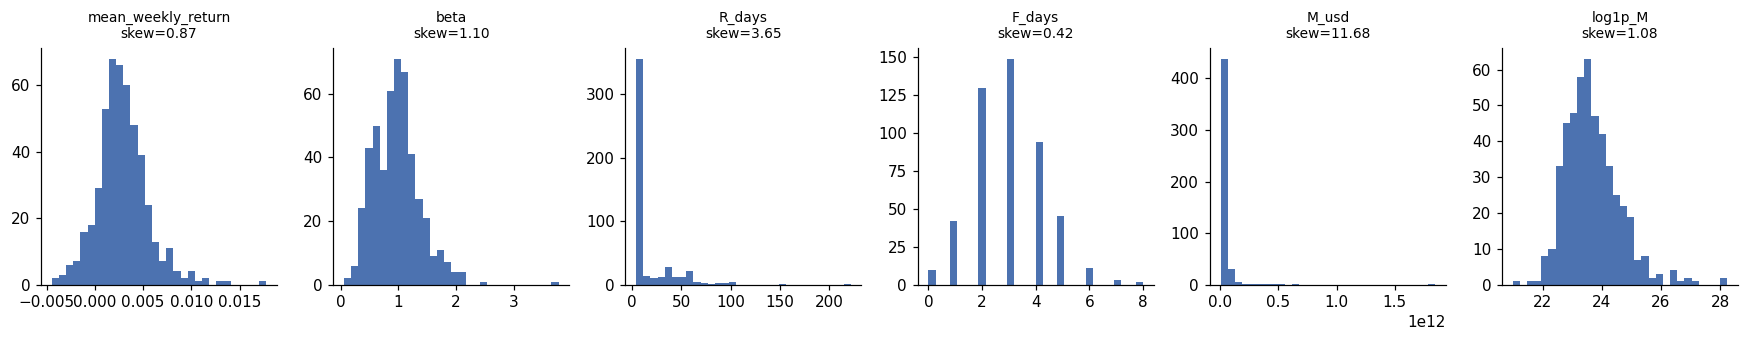

In [56]:
# Skew and outliers
def diag(frame):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75); iqr = q3 - q1
    out = ((frame < q1 - 1.5 * iqr) | (frame > q3 + 1.5 * iqr)).sum()
    return pd.DataFrame({"mean": frame.mean(), "median": frame.median(), "std": frame.std(),
                         "min": frame.min(), "max": frame.max(), "skew": frame.skew(), "IQR_outliers": out})

skew_tab = diag(df[RR_COLS + ["R_days", "F_days", "M_usd", "log1p_M"]])
skew_tab.to_csv(f"{OUT}/skew_outliers.csv")
show(skew_tab.assign(**{c: skew_tab[c].where(skew_tab.index != "M_usd", skew_tab[c] / 1e9) for c in ["mean", "median", "std", "min", "max"]}),
     "2.1 Skew and IQR outliers (M_usd row in USD billion)")
outl = pd.DataFrame({c: [f"{t} ({v:,.4g})" for t, v in df[c].abs().nlargest(3).items()] for c in ["mean_weekly_return", "beta", "R_days", "M_usd"]},
                    index=["1st", "2nd", "3rd"])
show(outl, "2.1 Largest outliers (kept: real shares, not data errors)")

fig, ax = plt.subplots(1, 6, figsize=(16, 3.2))
for a, c in zip(ax, RR_COLS + ["R_days", "F_days", "M_usd", "log1p_M"]):
    a.hist(df[c], bins=30, color="#4C72B0"); a.set_title(f"{c}\nskew={df[c].skew():.2f}", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/2_1_feature_distributions.png"); plt.show()

In [57]:
# Standardise each matrix separately
sc_rr, sc_rfm = StandardScaler(), StandardScaler()
X_rr = sc_rr.fit_transform(X_rr_raw)
X_rfm = sc_rfm.fit_transform(X_rfm_raw)
std_check = pd.DataFrame({"Mean": np.r_[X_rr.mean(0), X_rfm.mean(0)], "Std": np.r_[X_rr.std(0), X_rfm.std(0)]},
                         index=[f"RR: {c}" for c in RR_COLS] + [f"RFM: {c}" for c in RFM_COLS]).round(6) + 0.0
show(std_check, "2.1 Standardisation check (mean 0, std 1)", precision=3)
MATS = {"RR": (X_rr, X_rr_raw), "RFM": (X_rfm, X_rfm_raw)}

2.1 Standardisation check (mean 0, std 1)


,Mean,Std
RR: mean_weekly_return,0.0,1.0
RR: beta,0.0,1.0
RFM: R_days,0.0,1.0
RFM: F_days,0.0,1.0
RFM: log1p_M,0.0,1.0


## 2.2 Agglomerative clustering (Ward, Euclidean)


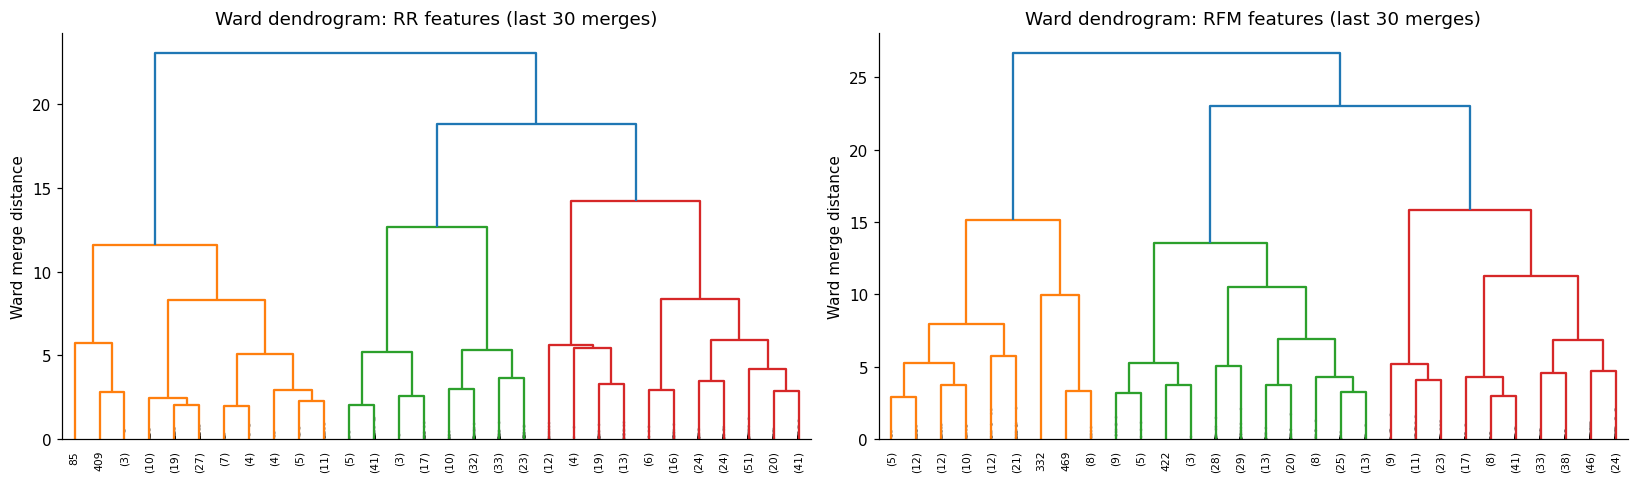

2.2 Ward RR: silhouette, cluster sizes and merge height gap by k


,silhouette,sizes,smallest,merge_gap
k,,,,
2,0.339,394/92,92,4.27
3,0.274,230/164/92,92,4.59
4,0.282,182/164/92/48,48,1.54
5,0.304,182/98/92/66/48,48,1.07
6,0.320,182/98/87/66/48/5,5,3.26
7,0.324,160/98/87/66/48/22/5,5,0.03
8,0.321,160/98/66/56/48/31/22/5,5,NaN


2.2 Ward RFM: silhouette, cluster sizes and merge height gap by k


,silhouette,sizes,smallest,merge_gap
k,,,,
2,0.368,404/82,82,3.72
3,0.304,250/154/82,82,7.14
4,0.289,207/154/82/43,43,0.69
5,0.305,207/154/72/43/10,10,1.57
6,0.314,207/136/72/43/18/10,10,2.29
7,0.292,141/136/72/66/43/18/10,10,0.76
8,0.302,141/79/72/66/57/43/18/10,10,NaN


In [58]:
def size_str(labels):
    return "/".join(str(x) for x in sorted(np.bincount(labels), reverse=True))

def ward_scan(X):
    rows = {}
    for k in K_RANGE:
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)
        rows[k] = {"silhouette": silhouette_score(X, lab), "sizes": size_str(lab),
                   "smallest": np.bincount(lab).min()}
    return pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ward_tabs = {}
for ax, (name, (X, _)) in zip(axes, MATS.items()):
    Z = linkage(X, method="ward", metric="euclidean")
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, leaf_font_size=7, show_contracted=True)
    ax.set_title(f"Ward dendrogram: {name} features (last 30 merges)"); ax.set_ylabel("Ward merge distance")
    ward_tabs[name] = ward_scan(X)
    top = Z[-8:, 2][::-1]
    ward_tabs[name]["merge_gap"] = pd.Series({k: top[k - 2] - top[k - 1] for k in range(2, 8)})
    ward_tabs[name].to_csv(f"{OUT}/2_2_ward_k_scan_{name}.csv")
plt.tight_layout(); plt.savefig(f"{FIG}/2_2_dendrograms.png"); plt.show()
for name in MATS:
    show(ward_tabs[name].rename_axis("k"), f"2.2 Ward {name}: silhouette, cluster sizes and merge height gap by k",
         fmt={"silhouette": "{:.3f}", "smallest": "{:.0f}", "merge_gap": "{:.2f}"})

In [59]:
# Suggested k: highest silhouette among solutions whose smallest cluster has at least 3% of shares.
# Review the profiles below; if a different k is more interpretable, set it here and justify it in the report.
MIN_SIZE = max(5, int(0.03 * len(df)))
def suggest(tab):
    ok = tab[tab["smallest"].astype(int) >= MIN_SIZE]
    return int((ok if len(ok) else tab)["silhouette"].astype(float).idxmax())

K_WARD_RR = suggest(ward_tabs["RR"])
K_WARD_RFM = suggest(ward_tabs["RFM"])
facts("2.2 Selected Ward k", {"Rule": f"highest silhouette with smallest cluster >= {MIN_SIZE} shares (3%)",
                             "Risk and return (RR)": K_WARD_RR, "RFM": K_WARD_RFM})

2.2 Selected Ward k


,Result
Check,
Rule,highest silhouette with smallest cluster >= 14...
Risk and return (RR),2
RFM,2


## 2.3 K means


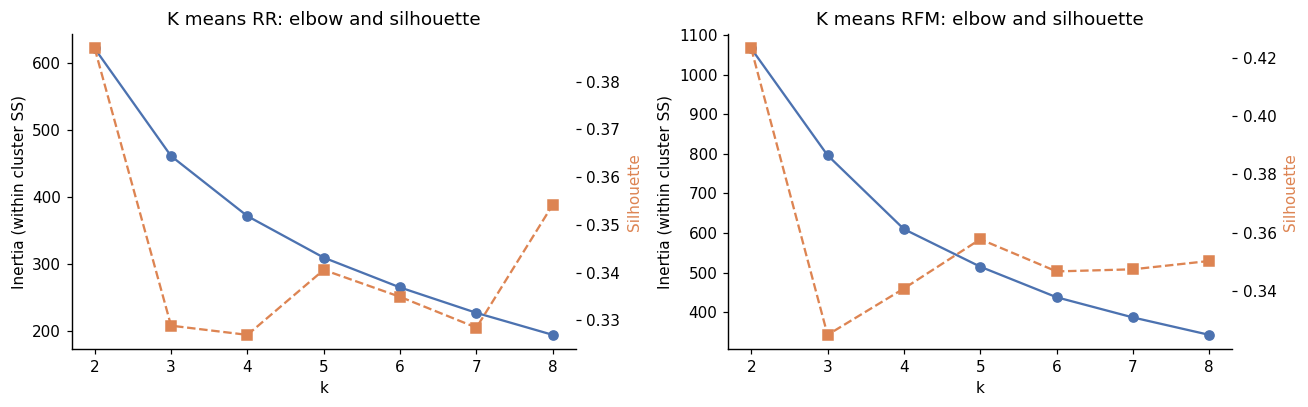

2.3 K means RR: silhouette, inertia and cluster sizes by k


,silhouette,inertia,sizes,smallest
k,,,,
2,0.387,621.6,343/143,143
3,0.329,461.2,202/165/119,119
4,0.327,371.6,160/154/132/40,40
5,0.341,309.6,166/131/112/50/27,27
6,0.335,265.1,156/127/105/50/43/5,5
7,0.328,227.2,128/103/85/77/47/41/5,5
8,0.354,194.4,136/79/78/76/43/40/29/5,5


2.3 K means RFM: silhouette, inertia and cluster sizes by k


,silhouette,inertia,sizes,smallest
k,,,,
2,0.423,"1,066.8",418/68,68
3,0.325,796.6,270/152/64,64
4,0.341,609.8,212/122/91/61,61
5,0.358,514.7,198/122/87/68/11,11
6,0.347,437.4,143/120/105/67/40/11,11
7,0.347,386.3,141/120/104/68/41/11/1,1
8,0.350,342.2,140/106/83/66/64/15/11/1,1


2.3 Selected K means k


,Result
Check,
Risk and return (RR),2
RFM,2


In [60]:
def km_scan(X):
    rows = {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        rows[k] = {"silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                   "sizes": size_str(km.labels_), "smallest": np.bincount(km.labels_).min()}
    return pd.DataFrame(rows).T

km_tabs = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, (X, _)) in zip(axes, MATS.items()):
    km_tabs[name] = km_scan(X); km_tabs[name].to_csv(f"{OUT}/2_3_kmeans_k_scan_{name}.csv")
    ax.plot(list(K_RANGE), km_tabs[name]["inertia"].astype(float), "o-", color="#4C72B0", label="Inertia")
    ax.set_xlabel("k"); ax.set_ylabel("Inertia (within cluster SS)"); ax.set_title(f"K means {name}: elbow and silhouette")
    ax2 = ax.twinx(); ax2.plot(list(K_RANGE), km_tabs[name]["silhouette"].astype(float), "s--", color="#DD8452")
    ax2.set_ylabel("Silhouette", color="#DD8452")
plt.tight_layout(); plt.savefig(f"{FIG}/2_3_kmeans_elbow_silhouette.png"); plt.show()
for name in MATS:
    show(km_tabs[name].rename_axis("k"), f"2.3 K means {name}: silhouette, inertia and cluster sizes by k",
         fmt={"silhouette": "{:.3f}", "inertia": "{:,.1f}", "smallest": "{:.0f}"})

K_KM_RR = suggest(km_tabs["RR"])
K_KM_RFM = suggest(km_tabs["RFM"])
facts("2.3 Selected K means k", {"Risk and return (RR)": K_KM_RR, "RFM": K_KM_RFM})

In [61]:
# Fit the four baseline solutions
labels = {
    "ward_RR": AgglomerativeClustering(n_clusters=K_WARD_RR, linkage="ward").fit_predict(X_rr),
    "kmeans_RR": KMeans(n_clusters=K_KM_RR, n_init=N_INIT, random_state=SEED).fit_predict(X_rr),
    "ward_RFM": AgglomerativeClustering(n_clusters=K_WARD_RFM, linkage="ward").fit_predict(X_rfm),
    "kmeans_RFM": KMeans(n_clusters=K_KM_RFM, n_init=N_INIT, random_state=SEED).fit_predict(X_rfm),
}
# Seed stability: refit K means with 5 other seeds and compare memberships
stab = {}
for name, X, k in [("RR", X_rr, K_KM_RR), ("RFM", X_rfm, K_KM_RFM)]:
    aris = [adjusted_rand_score(labels[f"kmeans_{name}"],
            KMeans(n_clusters=k, n_init=N_INIT, random_state=s).fit_predict(X)) for s in [1, 7, 21, 99, 123]]
    stab[f"K means {name} (k={k})"] = {"Seeds tested": "1, 7, 21, 99, 123", "Min ARI": min(aris), "Mean ARI": np.mean(aris)}
show(pd.DataFrame(stab).T, "2.3 K means seed stability (ARI 1 = identical clusters)", fmt={"Min ARI": "{:.3f}", "Mean ARI": "{:.3f}"})

2.3 K means seed stability (ARI 1 = identical clusters)


,Seeds tested,Min ARI,Mean ARI
K means RR (k=2),"1, 7, 21, 99, 123",1.000,1.000
K means RFM (k=2),"1, 7, 21, 99, 123",1.000,1.000


## 2.4 Cluster profiles and algorithm comparison

In [62]:
def profile(lab, cols):
    d = df.assign(cluster=lab)
    p = d.groupby("cluster")[cols].agg(["mean", "median"])
    p.insert(0, ("n", ""), d.groupby("cluster").size())
    return p

PROF_RR = RR_COLS
PROF_RFM = ["R_days", "F_days", "M_usd"]
profiles = {}
for key, lab in labels.items():
    cols = PROF_RR if key.endswith("RR") else PROF_RFM
    p = profile(lab, cols)
    if key.endswith("RFM"):
        p[("M_usd", "mean")] /= 1e9; p[("M_usd", "median")] /= 1e9
        p = p.rename(columns={"M_usd": "M_usd_bn"})
    profiles[key] = p; p.to_csv(f"{OUT}/2_4_profile_{key}.csv")
    show(p, f"2.4 {key} profile (original units; M in USD billion)")

2.4 ward_RR profile (original units; M in USD billion)


n mean_weekly_return            beta        
                           mean  median    mean  median
cluster                                                
0        394             0.0020  0.0021  0.8979  0.8817
1         92             0.0063  0.0055  1.2981  1.2177

2.4 kmeans_RR profile (original units; M in USD billion)


n mean_weekly_return            beta        
                           mean  median    mean  median
cluster                                                
0        143             0.0053  0.0049  1.3505  1.2781
1        343             0.0018  0.0019  0.8166  0.8340

2.4 ward_RFM profile (original units; M in USD billion)


n   R_days         F_days        M_usd_bn         
                 mean median    mean median     mean   median
cluster                                                      
0        404  12.7153   11.0  3.1708    3.0  37.8302  16.0473
1         82  58.3049   54.5  2.0976    2.0  47.1590  17.8490

2.4 kmeans_RFM profile (original units; M in USD billion)


n   R_days         F_days        M_usd_bn         
                 mean median    mean median     mean   median
cluster                                                      
0        418  13.4234   11.0  3.1866    3.0  32.6910  15.5696
1         68  63.3382   55.0  1.7794    2.0  80.6706  22.2500

2.4 PCA loadings and explained variance (total 79.4%)


,PC1,PC2
R_days,0.711,0.023
F_days,-0.650,0.402
log1p_M,0.268,0.915
Explained variance,0.458,0.336


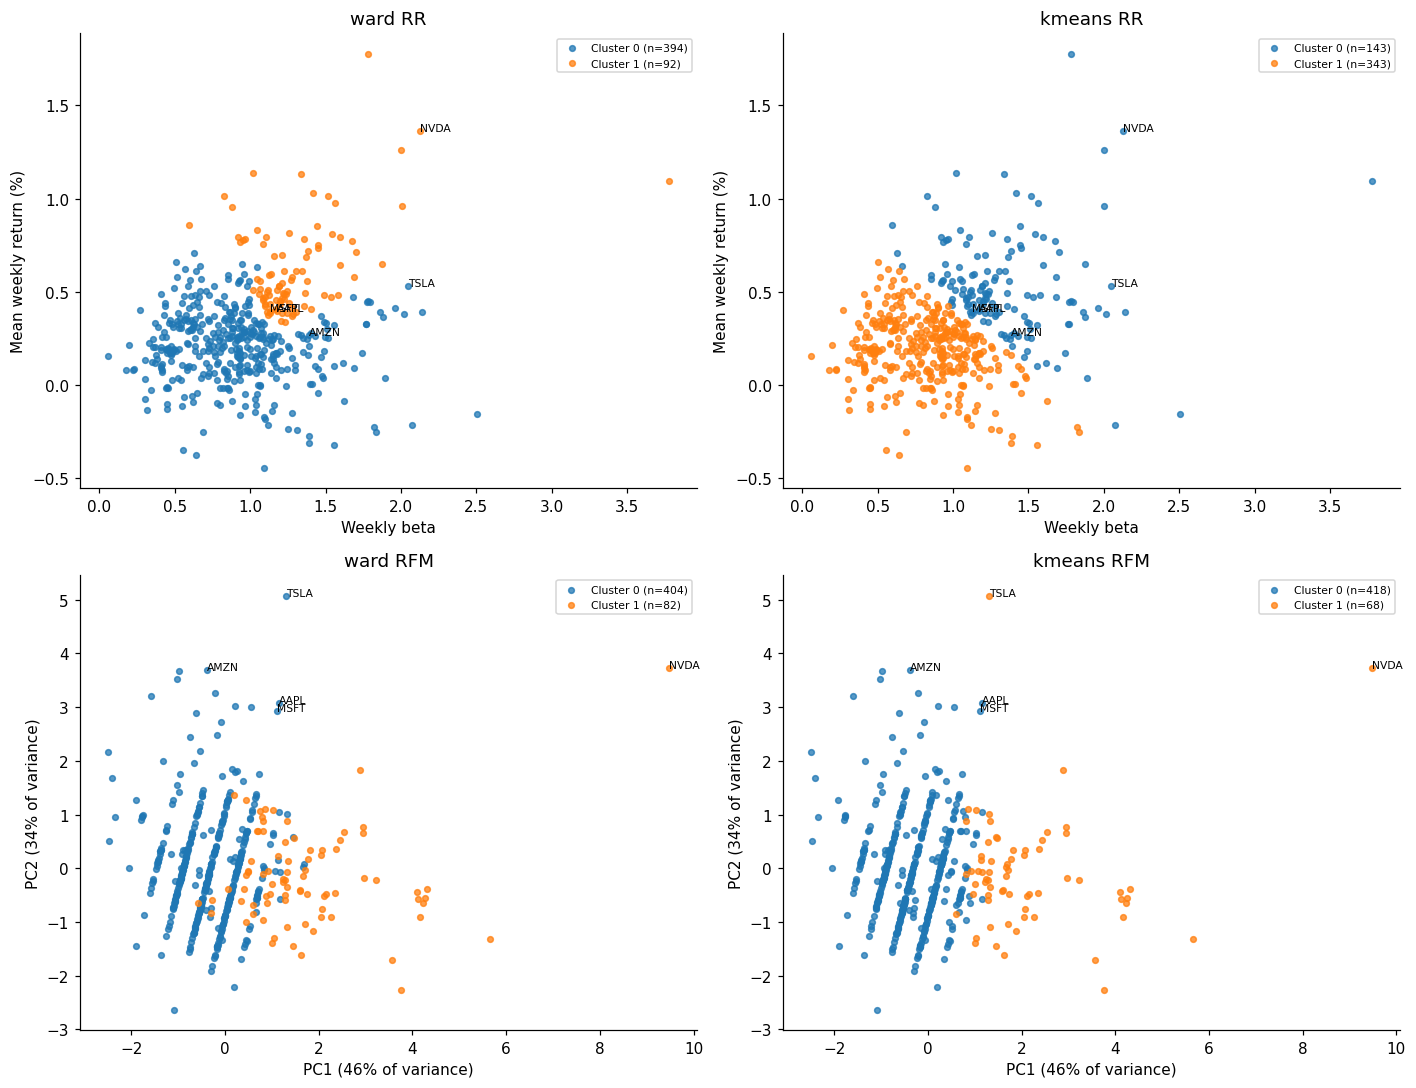

In [63]:
# 2D visuals. RR has only two features, so it is plotted directly in original units.
# RFM has three, so PCA on the standardised matrix projects it to 2D.
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
P = pca.transform(X_rfm); ev = pca.explained_variance_ratio_
pca_tab = pd.DataFrame(pca.components_.T, index=RFM_COLS, columns=["PC1", "PC2"])
pca_tab.loc["Explained variance"] = ev
show(pca_tab, f"2.4 PCA loadings and explained variance (total {ev.sum():.1%})", precision=3)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, key in zip(axes.ravel(), ["ward_RR", "kmeans_RR", "ward_RFM", "kmeans_RFM"]):
    lab = labels[key]
    if key.endswith("RR"):
        x, y = df["beta"], df["mean_weekly_return"] * 100
        ax.set_xlabel("Weekly beta"); ax.set_ylabel("Mean weekly return (%)")
    else:
        x, y = P[:, 0], P[:, 1]
        ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(np.asarray(x)[m], np.asarray(y)[m], s=14, alpha=0.75, label=f"Cluster {c} (n={m.sum()})")
    for t in df.assign(M=df.M_usd).nlargest(5, "M").index:   # label a few large names for orientation
        i = df.index.get_loc(t); ax.annotate(t, (np.asarray(x)[i], np.asarray(y)[i]), fontsize=7)
    ax.set_title(key.replace("_", " ")); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/2_4_cluster_scatter.png"); plt.show()

In [64]:
# Algorithm comparison on the same shares
comp = {
    "Ward vs K means (RR)": adjusted_rand_score(labels["ward_RR"], labels["kmeans_RR"]),
    "Ward vs K means (RFM)": adjusted_rand_score(labels["ward_RFM"], labels["kmeans_RFM"]),
    "RR vs RFM (Ward)": adjusted_rand_score(labels["ward_RR"], labels["ward_RFM"]),
    "RR vs RFM (K means)": adjusted_rand_score(labels["kmeans_RR"], labels["kmeans_RFM"]),
}
pd.Series(comp).to_csv(f"{OUT}/2_4_ari_comparisons.csv")
show(pd.Series(comp).rename("ARI").rename_axis("Comparison"), "2.4 Adjusted Rand index between solutions", precision=3)
show(pd.crosstab(labels["ward_RR"], labels["kmeans_RR"]).rename_axis(index="Ward RR", columns="K means RR"),
     "2.4 Crosstab: Ward RR (rows) vs K means RR (columns)", precision=0)
show(pd.crosstab(labels["ward_RFM"], labels["kmeans_RFM"]).rename_axis(index="Ward RFM", columns="K means RFM"),
     "2.4 Crosstab: Ward RFM (rows) vs K means RFM (columns)", precision=0)

# Sector composition (needed again in Task 3.2.1)
for key in ["ward_RR", "ward_RFM"]:
    sc = pd.crosstab(df["GICS Sector"], labels[key], normalize="columns").round(3)
    sc.to_csv(f"{OUT}/sector_share_{key}.csv")
    show(sc, f"Sector share by cluster, {key} (each column sums to 100%)", fmt="{:.1%}")

2.4 Adjusted Rand index between solutions


,ARI
Comparison,
Ward vs K means (RR),0.598
Ward vs K means (RFM),0.700
RR vs RFM (Ward),0.029
RR vs RFM (K means),0.004


2.4 Crosstab: Ward RR (rows) vs K means RR (columns)


K means RR,0,1
Ward RR,,
0,51,343
1,92,0


2.4 Crosstab: Ward RFM (rows) vs K means RFM (columns)


K means RFM,0,1
Ward RFM,,
0,396,8
1,22,60


Sector share by cluster, ward_RR (each column sums to 100%)


col_0,0,1
GICS Sector,,
Communication Services,3.8%,5.4%
Consumer Discretionary,9.1%,12.0%
Consumer Staples,8.1%,0.0%
Energy,4.1%,4.3%
Financials,15.5%,14.1%
Health Care,14.2%,2.2%
Industrials,14.5%,22.8%
Information Technology,11.4%,31.5%
Materials,5.1%,3.3%


Sector share by cluster, ward_RFM (each column sums to 100%)


col_0,0,1
GICS Sector,,
Communication Services,4.0%,4.9%
Consumer Discretionary,9.4%,11.0%
Consumer Staples,6.2%,8.5%
Energy,4.5%,2.4%
Financials,15.8%,12.2%
Health Care,12.1%,11.0%
Industrials,17.8%,7.3%
Information Technology,13.9%,22.0%
Materials,3.7%,9.8%


## 2.5 RFM sensitivity
### 2.5.1 Correlations among R, F and log1p(M)

2.5.1 Pearson correlations


,R_days,F_days,log1p_M
R_days,1.000,-0.346,0.152
F_days,-0.346,1.000,0.013
log1p_M,0.152,0.013,1.000


2.5.1 Spearman correlations


,R_days,F_days,log1p_M
R_days,1.000,-0.196,0.137
F_days,-0.196,1.000,-0.048
log1p_M,0.137,-0.048,1.000


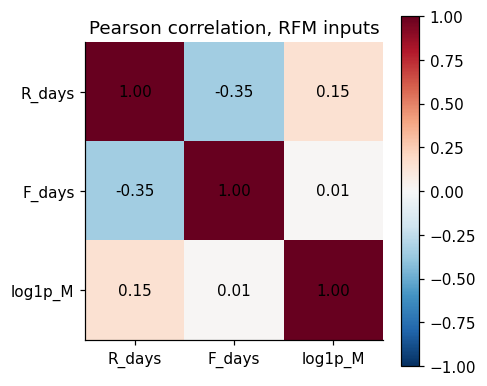

In [65]:
corr_p = df[RFM_COLS].corr(method="pearson")
corr_s = df[RFM_COLS].corr(method="spearman")
corr_p.to_csv(f"{OUT}/2_5_1_corr_pearson.csv"); corr_s.to_csv(f"{OUT}/2_5_1_corr_spearman.csv")
show(corr_p, "2.5.1 Pearson correlations", precision=3)
show(corr_s, "2.5.1 Spearman correlations", precision=3)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(corr_p, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3), RFM_COLS); ax.set_yticks(range(3), RFM_COLS)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr_p.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im); ax.set_title("Pearson correlation, RFM inputs")
plt.tight_layout(); plt.savefig(f"{FIG}/2_5_1_rfm_correlation.png"); plt.show()

### 2.5.2 Removal of Monetary


In [66]:
sc_rf = StandardScaler()
X_rf = sc_rf.fit_transform(df[["R_days", "F_days"]])
lab_rf = AgglomerativeClustering(n_clusters=K_WARD_RFM, linkage="ward").fit_predict(X_rf)
labels["ward_RF_noM"] = lab_rf
ari_noM = adjusted_rand_score(labels["ward_RFM"], lab_rf)
ct_noM = pd.crosstab(labels["ward_RFM"], lab_rf).rename_axis(index="Full RFM", columns="R and F only")

def tv_profile(lab):
    d = df.assign(cluster=lab)
    g = d.groupby("cluster")
    return pd.DataFrame({"n": g.size(), "R_mean": g.R_days.mean(), "F_mean": g.F_days.mean(),
                         "M_median_bn": g.M_usd.median() / 1e9, "M_mean_bn": g.M_usd.mean() / 1e9,
                         "M_min_bn": g.M_usd.min() / 1e9, "M_max_bn": g.M_usd.max() / 1e9})

tv_full, tv_rf = tv_profile(labels["ward_RFM"]), tv_profile(lab_rf)
tv_full.to_csv(f"{OUT}/2_5_2_traded_value_full.csv"); tv_rf.to_csv(f"{OUT}/2_5_2_traded_value_RF_only.csv")
# How much of M variance does each clustering explain? (eta squared on log1p M)
def eta2(lab, y):
    y = np.asarray(y); return 1 - sum(((y[lab == c] - y[lab == c].mean()) ** 2).sum() for c in np.unique(lab)) / ((y - y.mean()) ** 2).sum()
facts("2.5.2 Removal of Monetary (same shares, same k, standardised afresh)", {
    "k": K_WARD_RFM,
    "ARI full RFM vs R and F only": f"{ari_noM:.3f}",
    "Shares that changed cluster": int(len(lab_rf) - ct_noM.values[linear_sum_assignment(-ct_noM.values)].sum()),
    "Silhouette, R and F only": f"{silhouette_score(X_rf, lab_rf):.3f}",
    "Share of log1p(M) variance explained, full RFM": f"{eta2(labels['ward_RFM'], df.log1p_M):.2f}",
    "Share of log1p(M) variance explained, R and F only": f"{eta2(lab_rf, df.log1p_M):.2f}"})
show(ct_noM, "2.5.2 Crosstab: full RFM (rows) vs R and F only (columns)", precision=0)
show(tv_full, "2.5.2 Traded value profile, full RFM (M in USD billion)", precision=2)
show(tv_rf, "2.5.2 Traded value profile, R and F only (M in USD billion)", precision=2)

2.5.2 Removal of Monetary (same shares, same k, standardised afresh)


,Result
Check,
k,2
ARI full RFM vs R and F only,0.873
Shares that changed cluster,13
"Silhouette, R and F only",0.524
"Share of log1p(M) variance explained, full RFM",0.00
"Share of log1p(M) variance explained, R and F only",0.00


2.5.2 Crosstab: full RFM (rows) vs R and F only (columns)


R and F only,0,1
Full RFM,,
0,394,10
1,3,79


2.5.2 Traded value profile, full RFM (M in USD billion)


,n,R_mean,F_mean,M_median_bn,M_mean_bn,M_min_bn,M_max_bn
cluster,,,,,,,
0,404,12.72,3.17,16.05,37.83,1.30,1847.70
1,82,58.30,2.10,17.85,47.16,4.37,1825.34


2.5.2 Traded value profile, R and F only (M in USD billion)


,n,R_mean,F_mean,M_median_bn,M_mean_bn,M_min_bn,M_max_bn
cluster,,,,,,,
0,397,12.30,3.21,15.46,37.81,1.30,1847.70
1,89,56.56,2.01,20.85,46.53,4.37,1825.34


In [67]:
# Save all assignments
assign = df[["Security", "GICS Sector"] + RR_COLS + ["R_days", "F_days", "M_usd"]].copy()
for k, v in labels.items():
    assign[k] = v
assign.to_csv(f"{OUT}/cluster_assignments.csv")
facts("Saved cluster assignments", {"File": f"{OUT}/cluster_assignments.csv", "Rows": assign.shape[0], "Columns": assign.shape[1]})
show(assign.head(), "First rows of cluster_assignments.csv")

Saved cluster assignments


,Result
Check,
File,data_snapshot/task2/cluster_assignments.csv
Rows,486
Columns,12


First rows of cluster_assignments.csv


,Security,GICS Sector,mean_weekly_return,beta,R_days,F_days,M_usd,ward_RR,kmeans_RR,ward_RFM,kmeans_RFM,ward_RF_noM
ticker,,,,,,,,,,,,
MMM,3M,Industrials,0.0011,0.8691,11,4,2.599146e+10,0,1,0,0,0
AOS,A. O. Smith,Industrials,0.0020,1.0428,11,2,4.748980e+09,0,1,0,0,0
ABT,Abbott Laboratories,Health Care,0.0010,0.5835,11,1,3.523027e+10,0,1,0,0,0
ABBV,AbbVie,Health Care,0.0037,0.4254,11,3,6.837054e+10,0,1,0,0,0
ACN,Accenture,Information Technology,0.0024,1.1433,11,2,5.199430e+10,0,1,0,0,0


# Task 3: visuals and numbers for the Business Intelligence review


In [68]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
OUT = "data_snapshot/task3"; os.makedirs(OUT, exist_ok=True)
a = pd.read_csv("data_snapshot/task2/cluster_assignments.csv", index_col="ticker")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
show(a.head(), f"Cluster assignments loaded ({a.shape[0]} shares, {a.shape[1]} columns)")

Cluster assignments loaded (486 shares, 12 columns)


,Security,GICS Sector,mean_weekly_return,beta,R_days,F_days,M_usd,ward_RR,kmeans_RR,ward_RFM,kmeans_RFM,ward_RF_noM
ticker,,,,,,,,,,,,
MMM,3M,Industrials,0.0011,0.8691,11,4,2.599146e+10,0,1,0,0,0
AOS,A. O. Smith,Industrials,0.0020,1.0428,11,2,4.748980e+09,0,1,0,0,0
ABT,Abbott Laboratories,Health Care,0.0010,0.5835,11,1,3.523027e+10,0,1,0,0,0
ABBV,AbbVie,Health Care,0.0037,0.4254,11,3,6.837054e+10,0,1,0,0,0
ACN,Accenture,Information Technology,0.0024,1.1433,11,2,5.199430e+10,0,1,0,0,0


## 3.2.1 Cluster profiles in original units and sector composition

In [69]:
def prof(key):
    g = a.groupby(key)
    return pd.DataFrame({"n": g.size(),
        "mean_wk_ret_%": g.mean_weekly_return.mean() * 100, "beta": g.beta.mean(),
        "R_days_median": g.R_days.median(), "F_days_mean": g.F_days.mean(),
        "M_median_$bn": g.M_usd.median() / 1e9}).round(3)
for key in ["ward_RR", "ward_RFM"]:
    p = prof(key); p.to_csv(f"{OUT}/profile_{key}.csv")
    show(p, f"3.2.1 {key} cluster profile (original units)", precision=3)

3.2.1 ward_RR cluster profile (original units)


,n,mean_wk_ret_%,beta,R_days_median,F_days_mean,M_median_$bn
ward_RR,,,,,,
0,394,0.205,0.898,11.0,2.942,15.325
1,92,0.632,1.298,11.0,3.196,24.184


3.2.1 ward_RFM cluster profile (original units)


,n,mean_wk_ret_%,beta,R_days_median,F_days_mean,M_median_$bn
ward_RFM,,,,,,
0,404,0.286,0.967,11.0,3.171,16.047
1,82,0.286,1.009,54.5,2.098,17.849


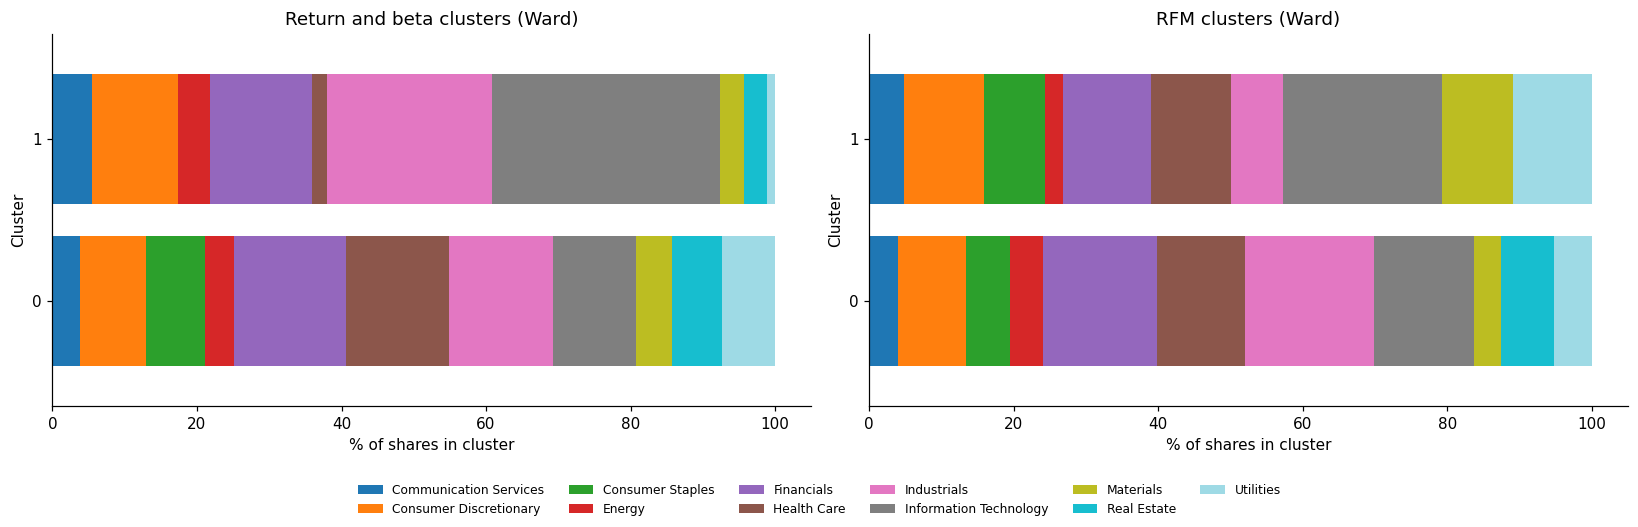

3.2.1 ward_RR: top sector per cluster


,Top sector,Share of cluster
ward_RR,,
0,Financials,15.5%
1,Information Technology,31.5%


3.2.1 ward_RFM: top sector per cluster


,Top sector,Share of cluster
ward_RFM,,
0,Industrials,17.8%
1,Information Technology,22.0%


3.2.1 Overall sector mix


,Share of all shares
GICS Sector,
Industrials,16.0%
Information Technology,15.2%
Financials,15.2%
Health Care,11.9%
Consumer Discretionary,9.7%
Consumer Staples,6.6%
Utilities,6.2%
Real Estate,6.2%
Materials,4.7%


In [70]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, key, title in zip(axes, ["ward_RR", "ward_RFM"], ["Return and beta clusters (Ward)", "RFM clusters (Ward)"]):
    comp = pd.crosstab(a[key], a["GICS Sector"], normalize="index") * 100
    comp.plot(kind="barh", stacked=True, ax=ax, colormap="tab20", width=0.8, legend=False)
    ax.set_xlabel("% of shares in cluster"); ax.set_ylabel("Cluster"); ax.set_title(title)
    comp.round(1).to_csv(f"{OUT}/sector_pct_{key}.csv")
handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, loc="lower center", ncol=6, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.1, 1, 1]); plt.savefig(f"{OUT}/3_2_1_sector_composition.png"); plt.show()

# Dominant sector per cluster and the overall sector mix, for the text
for key in ["ward_RR", "ward_RFM"]:
    ct = pd.crosstab(a[key], a["GICS Sector"], normalize="index")
    show(pd.DataFrame({"Top sector": ct.idxmax(axis=1), "Share of cluster": ct.max(axis=1)}), f"3.2.1 {key}: top sector per cluster",
         fmt={"Share of cluster": "{:.1%}"})
show(a["GICS Sector"].value_counts(normalize=True).rename("Share of all shares"), "3.2.1 Overall sector mix", fmt="{:.1%}")

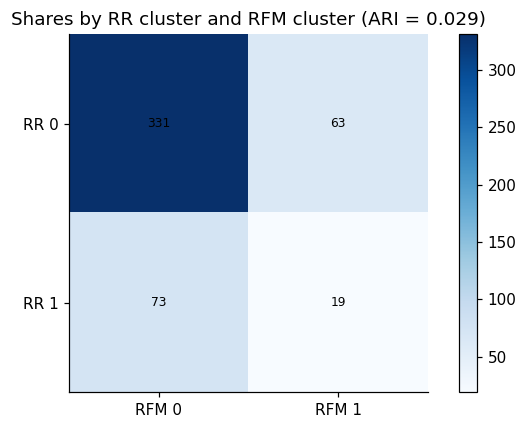

In [71]:
# Do risk/return groups and activity groups overlap? Heatmap of shares in each pair of clusters
ct = pd.crosstab(a.ward_RR, a.ward_RFM)
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(ct, cmap="Blues")
ax.set_xticks(range(ct.shape[1]), [f"RFM {c}" for c in ct.columns]); ax.set_yticks(range(ct.shape[0]), [f"RR {c}" for c in ct.index])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, ct.iloc[i, j], ha="center", va="center", fontsize=8)
ax.set_title(f"Shares by RR cluster and RFM cluster (ARI = {adjusted_rand_score(a.ward_RR, a.ward_RFM):.3f})")
plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{OUT}/3_2_1_RR_vs_RFM.png"); plt.show()

## 3.2.2 Sensitivity findings

3.2.2 Pearson correlations among R, F and log1p(M)


,R_days,F_days,log1p_M
R_days,1.000,-0.346,0.152
F_days,-0.346,1.000,0.013
log1p_M,0.152,0.013,1.000


3.2.2 Removal of Monetary


,Result
Check,
ARI full RFM vs R and F only,0.873


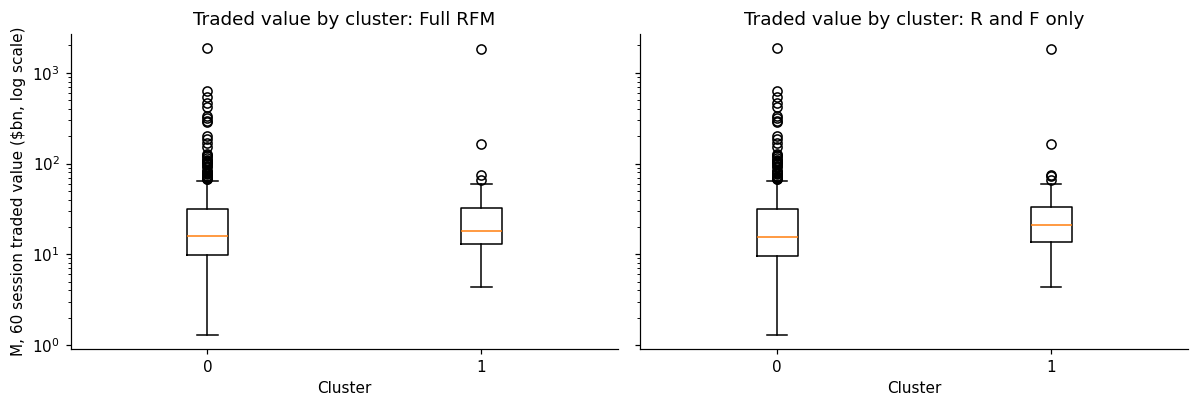

In [72]:
d = a.assign(log1p_M=np.log1p(a.M_usd))
show(d[["R_days", "F_days", "log1p_M"]].corr(), "3.2.2 Pearson correlations among R, F and log1p(M)", precision=3)
facts("3.2.2 Removal of Monetary", {"ARI full RFM vs R and F only": f"{adjusted_rand_score(a.ward_RFM, a.ward_RF_noM):.3f}"})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, t in zip(axes, ["ward_RFM", "ward_RF_noM"], ["Full RFM", "R and F only"]):
    groups = [a.loc[a[key] == c, "M_usd"] / 1e9 for c in sorted(a[key].unique())]
    ax.boxplot(groups, tick_labels=[str(c) for c in sorted(a[key].unique())])
    ax.set_yscale("log"); ax.set_xlabel("Cluster"); ax.set_title(f"Traded value by cluster: {t}")
axes[0].set_ylabel("M, 60 session traded value ($bn, log scale)")
plt.tight_layout(); plt.savefig(f"{OUT}/3_2_2_traded_value_noM.png"); plt.show()

In [73]:
# Zip all outputs for download
import shutil
shutil.make_archive("data_snapshot", "zip", "data_snapshot")
try:
    from google.colab import files
    files.download("data_snapshot.zip")
except ImportError:
    print("Saved data_snapshot.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>